# EDA
Задачи для начала: определить задачи для модели машиного обучения, скачать датасет, разобраться из чего он состоит, изучить признаки

Задача проекта: научиться предсказывать потребление електрическтва для здания с определёнными признаками. 
Дата сет лежит по ссылке: https://www.kaggle.com/datasets/claytonmiller/buildingdatagenomeproject2 

## скачивание дата сета 

In [109]:
import matplotlib.pyplot as plt

In [21]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
from pathlib import Path
import pandas as pd


file_path = Path.cwd()/'dataset'

path = Path(kagglehub.dataset_download("claytonmiller/buildingdatagenomeproject2"))
print(*list(path.glob("*")), sep = f'\n')

/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/hotwater.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/gas.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/solar.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/chilledwater_cleaned.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/electricity.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/steam_cleaned.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/water.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/hotwater_cleaned.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/chilledwater.csv
/Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingda

In [36]:
!mkdir  ./dataset
!mv /Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/* ./dataset
#перенос таблиц в папку проекта

mkdir: ./dataset: File exists
zsh:1: no matches found: /Users/ila/.cache/kagglehub/datasets/claytonmiller/buildingdatagenomeproject2/versions/3/*


## изучение таблиц

   В репозитории лежит 18 scv файлов, 18 таблиц. 2 таблицы с общими данными: "metadata" и "weather". В первой информация об каждом из 1636 зданий (строки). 32 колонки с информацией о зданиях. Во второй разные показания метеологических датчиков (столбцы, 32 значения) для 19 локаций и 17544 часов (показания за каждый час двух лет) (19х17544 строки)
   Остальные таблицы продублированны на обработанные "..._cleaned.csv" и сырые. В обработанных на None заменены: выбросы, сломанные датчики и нулевые показания. Таблицы хранят в себе показания датчиков за каждый час (17544 строки), не для всех зданий. Названия таблиц: 'electricity.csv', 'hotwater.csv', 'gas.csv', 'solar.csv', 'chilledwater.csv', 'irrigation.csv', 'water.csv', 'steam.csv'.

   В своём проекте я возьму сразу обработанные данные. Рассмотрю таблицы подробнее.

In [80]:
tables_names = ['electricity_cleaned.csv', 'hotwater_cleaned.csv', 'gas_cleaned.csv', 'solar_cleaned.csv', 'chilledwater_cleaned.csv', 'irrigation_cleaned.csv', 'water_cleaned.csv', 'steam_cleaned.csv']
pd.set_option('display.max_columns', 4)
pd.set_option('display.width', 1000)

for x in tables_names:
    path_test = Path.cwd()/'data'/x
    df = pd.read_csv(path_test)
    print (x, f'количество объектов для которых показатели определенны: {df.shape[1]}', f'процент пропусков {(1-(df.describe().sum(axis = 1).iloc[0]/(df.shape[0]*df.shape[1])))*100:.2f}%', sep = f'\n' , end = f'\n\n')

electricity_cleaned.csv
количество объектов для которых показатели определенны: 1579
процент пропусков 8.99%

hotwater_cleaned.csv
количество объектов для которых показатели определенны: 186
процент пропусков 7.92%

gas_cleaned.csv
количество объектов для которых показатели определенны: 178
процент пропусков 5.31%

solar_cleaned.csv
количество объектов для которых показатели определенны: 6
процент пропусков 34.77%

chilledwater_cleaned.csv
количество объектов для которых показатели определенны: 556
процент пропусков 7.93%

irrigation_cleaned.csv
количество объектов для которых показатели определенны: 38
процент пропусков 14.21%

water_cleaned.csv
количество объектов для которых показатели определенны: 147
процент пропусков 7.57%

steam_cleaned.csv
количество объектов для которых показатели определенны: 371
процент пропусков 12.42%



В таблицы solar и irrigation определенны для менее 100 объектов (6% от всего количества зданий). Water, gas, hotwater до 200 объектов (12%). Steam для 23%, chilledwater для 35%. Electricity для 96%.

Рассмотрю таблицу metadata.csv. 

In [106]:
df = pd.read_csv(Path.cwd()/'data'/'metadata.csv')
print( f"metadata.csv \n {df.shape} \n")
for colum in df.columns:
    print(f"{colum} отсутствует {(df.shape[0]-df[colum].count())*100/df.shape[0]:.2f}% \n ")
    print(

metadata.csv 
 (1636, 32) 

building_id пропущенно 0.00% 
 
site_id пропущенно 0.00% 
 
building_id_kaggle пропущенно 11.43% 
 
site_id_kaggle пропущенно 2.26% 
 
primaryspaceusage пропущенно 1.28% 
 
sub_primaryspaceusage пропущенно 1.28% 
 
sqm пропущенно 0.00% 
 
sqft пропущенно 0.00% 
 
lat пропущенно 14.49% 
 
lng пропущенно 14.49% 
 
timezone пропущенно 0.00% 
 
electricity пропущенно 3.55% 
 
hotwater пропущенно 88.69% 
 
chilledwater пропущенно 66.08% 
 
steam пропущенно 77.38% 
 
water пропущенно 91.08% 
 
irrigation пропущенно 97.74% 
 
solar пропущенно 99.69% 
 
gas пропущенно 89.18% 
 
industry пропущенно 64.61% 
 
subindustry пропущенно 64.61% 
 
heatingtype пропущенно 86.86% 
 
yearbuilt пропущенно 50.06% 
 
date_opened пропущенно 98.72% 
 
numberoffloors пропущенно 73.04% 
 
occupants пропущенно 85.94% 
 
energystarscore пропущенно 90.04% 
 
eui пропущенно 81.72% 
 
site_eui пропущенно 90.04% 
 
source_eui пропущенно 90.04% 
 
leed_level пропущенно 99.02% 
 
rating пропу

В этом файле храниться следующая информация о зданиях: площадь, назначение площади, отрасль, координаты города, наличие различных счётчиков, тип отопления, дата постройки и начала эксплатации, кол-во людей находящихся в здании, оценка энергоэффективности, интенсивность потребление энергии.

## Определение цели проекта 

Я хочу спроецировать цель проекта на настоящую бизнес процесс. Вот такие примерно задачи можно решить:

   Электричество:
- По этомк датасету проводилось соревнование и целью было **прогнозирование потребления зданием энергии (на длительный срок)** если его не реконструировать энергосберегающим оборудованием. Соревнования организовывала некомерческая компания которая занимается разработкой систем снабжения здания.
-  **прогнозирование потребление электроэнергии на следующую неделю или день**. Полезно для компаний распределяющими электричество.
-  **Расчёт потребления энергии при отсутствии части данных от счётчика**. Интерес для компании которая продаёт электричество.
-  **Подсчёт электрическа которое здание в среднем потребляет с такими характеристиками**. Полезно для выявления не эффективного потребления например утечек энергии. Полезно для управляющих компаний.

Назначение здания:
- **определение для чего используется здание**. Полезно для компании продающей электричество, воду, газ. Часто тарифы для комерческой деятельности отличаются.

Для определения цели надо определить специфику датасета:

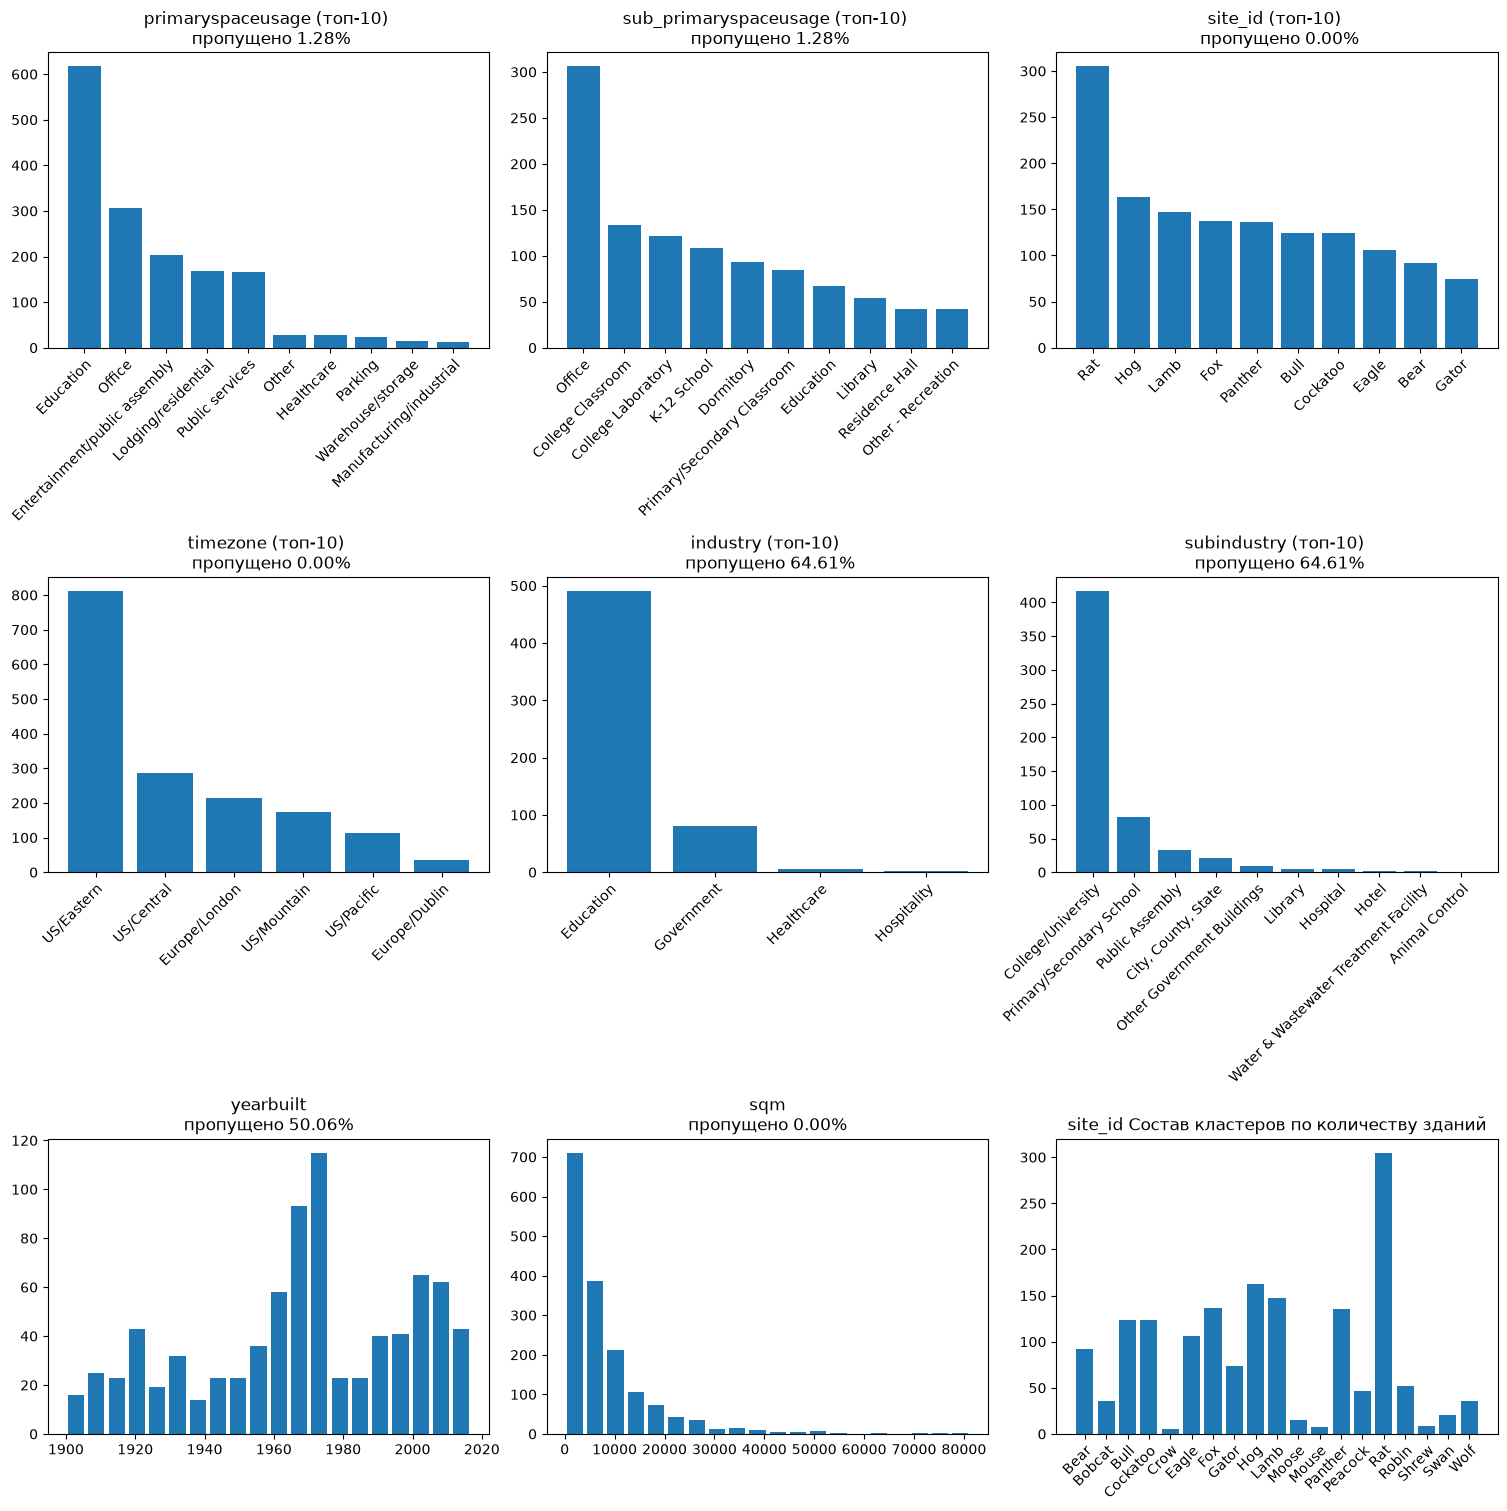

In [153]:
bar_cols  = ['primaryspaceusage', 'sub_primaryspaceusage', 'site_id', 'timezone', 'industry', 'subindustry']
hist_cols = ['yearbuilt', 'sqm']

fig, axes = plt.subplots(3, 3, figsize=(15, 15), constrained_layout=True)
cells = iter(axes.flat)

for col in bar_cols:
    ax, counts = next(cells), df[col].value_counts().head(10)
    ax.bar(counts.index, counts.values)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    ax.set_title(f'{col} (топ-10) \n пропущено {df[col].isna().mean():.2%}')

for col in hist_cols:
    ax = next(cells)
    ax.hist(df[col].dropna(), bins=20, rwidth=0.8)
    ax.set_title(f'{col} \n пропущено {df[col].isna().mean():.2%}')

buldings_in_site = df.groupby('site_id')['building_id'].count()
axes[2, 2].bar(buldings_in_site.index, buldings_in_site.values)
axes[2, 2].set_title(f'site_id Состав кластеров по количеству зданий')
plt.setp(axes[2, 2].get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

plt.show()

Цель проекта: Спрогнозировать потребление зданием электроэнергии на след день. Я приму что действую как компания сбывающая электричество (покупает оптом и продаёт в розницу каждому зданию). Для таких компаний характерно прогнозировать потребление не для каждого здания индивидуально а для района. А временной промежуток за который прогнозируют потребление бывает разный и отличается в зависимости от того для чего будет использован прогноз. Для закупок, договоров, ремонтов рассматривают интервал в порядках недели/месяца. Для балансировки нагрузки и потребления берут интервал в пределах минут/часах.

Определить принятые интервал и район. 